# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?

The population of all six continents increased between 1970 and 2022, but at different rates and
Africa experienced the fastest relative population growth, increasing by approximately 290.41% compared with its 1970 population.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*


I selected a line chart because it clearly shows population growth over time. It allows us to compare the growth trends of all six continents relative to their 1970 population. Different colours make the continents easy to distinguish and help identify Africa as the fastest-growing continent.

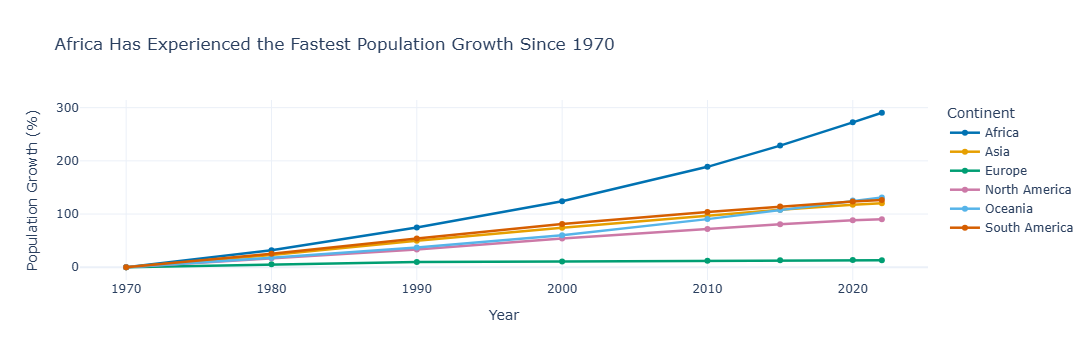

In [2]:
# Q1
# YOUR CODE HERE

continent_pop = df_long.groupby(
    ['Continent', 'Year']
)['Population'].sum().reset_index()

baseline = continent_pop[continent_pop['Year'] == 1970][
    ['Continent', 'Population']
].rename(columns={'Population': 'Population_1970'})

continent_pop = continent_pop.merge(baseline, on='Continent')


continent_pop['Growth (%)'] = (
    (continent_pop['Population'] - continent_pop['Population_1970'])
    / continent_pop['Population_1970']
) * 100


fig = px.line(
    continent_pop,
    x='Year',
    y='Growth (%)',
    color='Continent',
    markers=True,
    color_discrete_sequence=[
        '#0072B2', '#E69F00', '#009E73',
        '#CC79A7', '#56B4E9', '#D55E00'
    ],
    title='Africa Has Experienced the Fastest Population Growth Since 1970'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Year',
    yaxis_title='Population Growth (%)',
    legend_title='Continent'
)

fig.update_traces(line=dict(width=2.5))

fig.show()


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

Answer:The 15 countries that added the most people between 1970 and 2022 are India, China, Pakistan, Nigeria, Indonesia, United States, Brazil, Bangladesh, Ethiopia, DR Congo, Philippines, Mexico, Egypt, Iran, and Vietnam.

Four countries are in Africa: Nigeria, Ethiopia, DR Congo, and Egypt.

India recorded the highest population increase, adding approximately 860 million people during this period.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a sorted horizontal bar chart because it clearly compares the population increase of the top 15 countries between 1970 and 2022. The bars are arranged in descending order to make country rankings easy to understand.

Number of African countries: 4


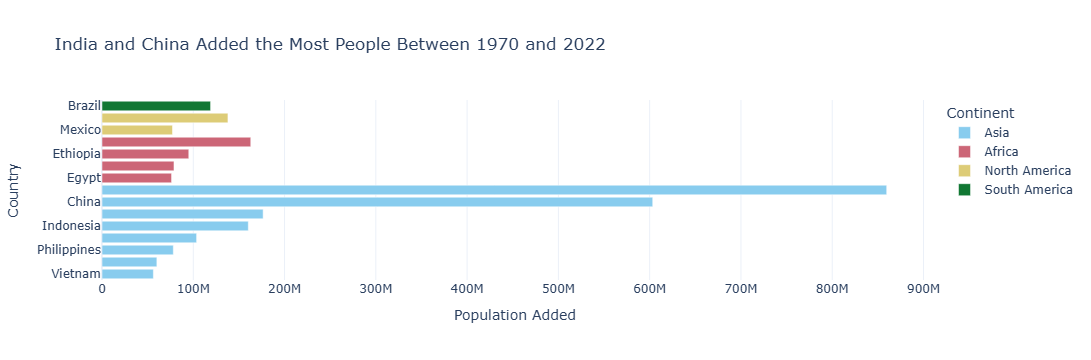

In [4]:
# Q2
# YOUR CODE HERE


df['Population Added'] = (
    df['2022 Population'] - df['1970 Population']
)

top_15 = df.nlargest(15, 'Population Added')


africa_count = (top_15['Continent'] == 'Africa').sum()

print("Number of African countries:", africa_count)

fig = px.bar(
    top_15.sort_values('Population Added'),
    x='Population Added',
    y='Country',
    color='Continent',
    orientation='h',
    title='India and China Added the Most People Between 1970 and 2022',
    color_discrete_sequence=px.colors.qualitative.Safe
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Population Added',
    yaxis_title='Country',
    legend_title='Continent'
)

fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

There is a moderate positive relationship between a country's land area and its 2022 population: generally, countries with larger land areas tend to have larger populations, but this is not always the case.

The relationship differs across continents. It is more noticeable in Asia, while the pattern is weaker in Africa. India and China follow the general pattern, with both large land areas and very large populations.

Countries that clearly break the pattern:

Canada, Russia and Australia: Very large land areas but comparatively smaller populations.

Bangladesh: A relatively small land area but a very large population.

Japan: A comparatively smaller land area with a population exceeding 123 million.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a scatter plot because it effectively shows the relationship between two numerical variables: land area and 2022 population. Each point represents a country, and different colours distinguish the continents.

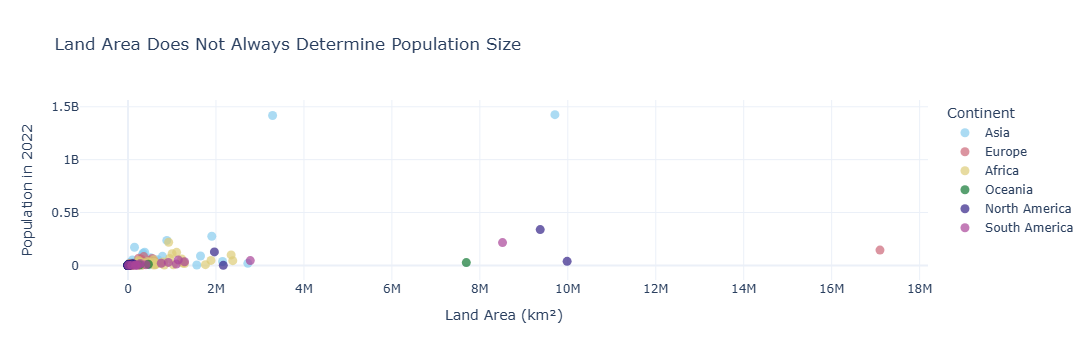

In [5]:
# Q3
# YOUR CODE HERE

# Q3: Do bigger countries have more people?

fig = px.scatter(
    df,
    x='Area',
    y='2022 Population',
    color='Continent',
    hover_name='Country',
    title='Land Area Does Not Always Determine Population Size',
    color_discrete_sequence=px.colors.qualitative.Safe
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Land Area (km²)',
    yaxis_title='Population in 2022',
    legend_title='Continent'
)

fig.update_traces(
    marker=dict(size=9, opacity=0.7)
)

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

Answer:
Population density varies considerably within and across continents. Asia has some of the highest population densities, particularly in countries such as Bangladesh and India. Africa and Europe also show considerable variation between countries. South America and Oceania generally have lower population densities.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a violin plot because it shows the distribution and spread of population density across continents, rather than only comparing average values. The inner box plot highlights the median and quartiles, while the outlier points identify countries with unusually high population density.

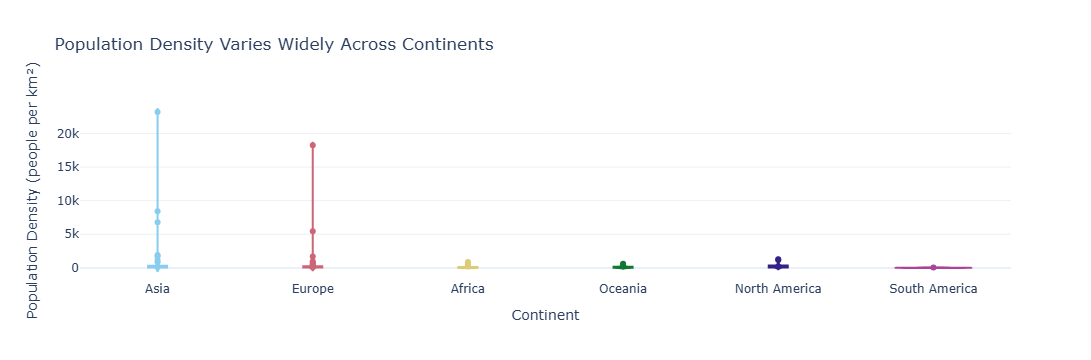

In [8]:
# Q4
# YOUR CODE HERE

fig = px.violin(
    df,
    x='Continent',
    y='Density',
    color='Continent',
    box=True,
    points='outliers',
    title='Population Density Varies Widely Across Continents',
    color_discrete_sequence=px.colors.qualitative.Safe
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Continent',
    yaxis_title='Population Density (people per km²)',
    showlegend=False
)

fig.show()


---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

Between 2000 and 2022, 200 countries experienced population growth, while 34 countries experienced a population decline. Qatar recorded the highest percentage growth, while the Northern Mariana Islands recorded the largest percentage decline in this dataset. The map highlights geographical differences in population change, showing that growth and decline vary considerably across countries.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a choropleth map because it displays population percentage change across countries geographically. The colour scale uses different shades to distinguish population growth from population decline, with zero as the midpoint

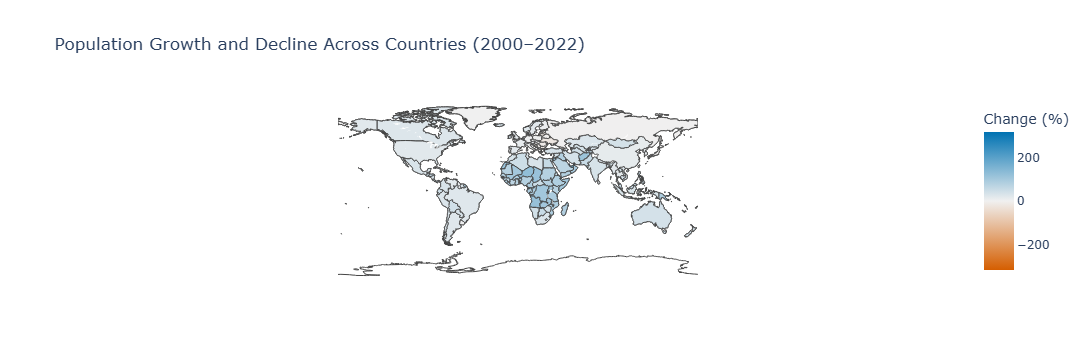

In [10]:
# Q5
# YOUR CODE HERE

df['Population Change (%)'] = (
    (df['2022 Population'] - df['2000 Population'])
    / df['2000 Population']
) * 100

fig = px.choropleth(
    df,
    locations='CCA3',
    locationmode='ISO-3',
    color='Population Change (%)',
    hover_name='Country',
    hover_data={
        '2000 Population': True,
        '2022 Population': True,
        'Population Change (%)': ':.2f',
        'CCA3': False
    },
    color_continuous_scale=[
        '#D55E00', '#F0F0F0', '#0072B2'
    ],
    color_continuous_midpoint=0,
    title='Population Growth and Decline Across Countries (2000–2022)'
)

fig.update_layout(
    template='plotly_white',
    geo=dict(showframe=False, showcoastlines=True),
    coloraxis_colorbar_title='Change (%)'
)

fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

The 2022 world population is unevenly distributed across continents. Asia has the largest share, accounting for approximately 59% of the total world population, followed by Africa with around 18% and Europe with around 9%. North America, South America and Oceania make up the remaining share.

At the country level, India and China are the largest contributors, with approximately 1.42 billion people each. Other major contributors include the United States, Indonesia, Pakistan, Nigeria and Brazil.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a treemap because it displays hierarchical data at two levels: continents and their countries. The size of each rectangle represents the country's 2022 population, making it easy to compare population contributions.


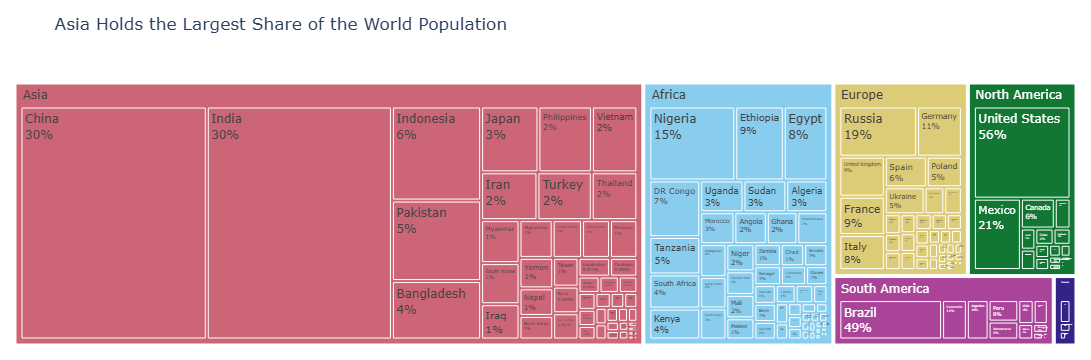

In [11]:
# Q6
# YOUR CODE HERE


fig = px.treemap(
    df,
    path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_sequence=px.colors.qualitative.Safe,
    title='Asia Holds the Largest Share of the World Population'
)

fig.update_layout(
    template='plotly_white',
    margin=dict(t=60, l=10, r=10, b=10)
)

fig.update_traces(
    textinfo='label+percent parent',
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Population: %{value:,.0f}<br>'
        'Share of parent: %{percentParent:.1%}'
        '<extra></extra>'
    )
)

fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

Between 1970 and 2022, Africa's share of the world population increased significantly, from approximately 9.9% to 17.9%. Asia continued to hold the largest share, increasing slightly from 58.1% to 59.2%. In contrast, Europe's share declined considerably, from 17.8% to 9.3%. The Rest of the world share also decreased slightly, from 14.3% to 13.6%.

Overall, Africa experienced the largest increase in its share, while Europe experienced the largest decline. Asia remained the dominant continent in terms of population share.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

I chose a 100% stacked bar chart because it shows how each continent group contributes to the total world population over time. Each bar represents 100% of the population for a particular year, making it easy to compare changes in population shares.

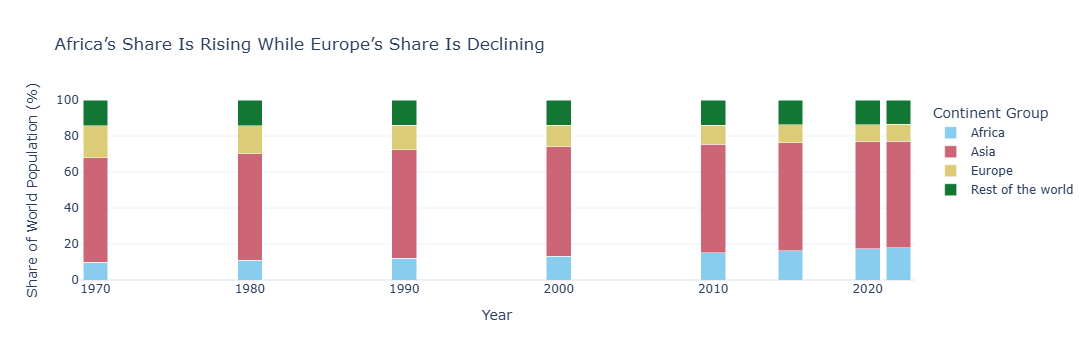

In [12]:
# Q7
# YOUR CODE HERE


df_long['Continent Group'] = df_long['Continent'].replace({
    'North America': 'Rest of the world',
    'South America': 'Rest of the world',
    'Oceania': 'Rest of the world'
})

continent_pop = df_long.groupby(
    ['Year', 'Continent Group']
)['Population'].sum().reset_index()

continent_pop['World Share (%)'] = (
    continent_pop['Population']
    / continent_pop.groupby('Year')['Population'].transform('sum')
) * 100

fig = px.bar(
    continent_pop,
    x='Year',
    y='World Share (%)',
    color='Continent Group',
    barmode='stack',
    title='Africa’s Share Is Rising While Europe’s Share Is Declining',
    color_discrete_sequence=px.colors.qualitative.Safe
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Year',
    yaxis_title='Share of World Population (%)',
    legend_title='Continent Group'
)

fig.update_yaxes(range=[0, 100])

fig.show()